# Module 10, Part 4: Interpretability, calibration, robustness and shift

This notebook is the runnable companion to Part 4 of the Module 10 learning content. A model that scores well on a test set can still be unexplained, overconfident and brittle. We test four things.

1. **Where is the model looking?** Grad-CAM, gradient saliency and occlusion on a small convolutional network, plus a sanity check that the explanation depends on what the model learned.
2. **Exact Shapley values** for a small tabular model, and the property that makes them attractive: the contributions add up to the prediction.
3. **Calibration**: whether a confidence of 0.9 means 90% right, measured by the expected calibration error and a reliability table, and a one-number repair, temperature scaling.
4. **Robustness and shift**: accuracy under noise, blur, occlusion, a shift of the image, and whether the model's own confidence can warn us.

**Setting.** The 8 by 8 digits. A small CNN (two convolution layers, 93% test accuracy) for the image explanations; a deliberately overfitted multilayer perceptron for calibration. Everything is CPU only and seeded.

In [1]:
import itertools, copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_digits_split(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te])


def lending_data(n=6000, seed=0, label_bias=1.0, proxy_strength=0.8):
    """A synthetic loan data set in which the truth is known.

    Each applicant has a hidden creditworthiness, a group (0 or 1), and observed features. The group is
    NOT given to the model as a feature, but `neighbourhood` is a proxy for it. Historical approvals
    (the label we train on) were biased against group 1 by `label_bias` units of credit score, whereas
    the real repayment outcome depends only on creditworthiness.
    Returns a dict of numpy arrays: X, group, y_hist (biased label), y_true (repayment), names.
    """
    rng = np.random.default_rng(seed)
    group = (rng.random(n) < 0.4).astype(int)
    credit = rng.normal(0.0, 1.0, n)                        # same distribution in both groups
    income = 0.8 * credit + rng.normal(0, 0.6, n)
    history = 0.7 * credit + rng.normal(0, 0.7, n)
    debt = -0.5 * credit + rng.normal(0, 0.8, n)
    noise = rng.normal(0, 1, n)
    neighbourhood = proxy_strength * (group - 0.4) / 0.49 + np.sqrt(1 - proxy_strength ** 2) * rng.normal(0, 1, n)
    X = np.stack([income, history, debt, neighbourhood, noise], 1).astype(np.float32)
    y_true = (credit + rng.normal(0, 0.5, n) > 0).astype(int)           # repays the loan
    y_hist = (credit - label_bias * group + rng.normal(0, 0.5, n) > 0).astype(int)  # biased past approvals
    return dict(X=X, group=group, y_hist=y_hist, y_true=y_true,
                names=["income", "payment history", "debt", "neighbourhood", "noise"])

In [3]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(sizes):
    layers = []
    for i in range(len(sizes) - 2):
        layers += [nn.Linear(sizes[i], sizes[i + 1]), nn.ReLU()]
    layers += [nn.Linear(sizes[-2], sizes[-1])]
    return nn.Sequential(*layers)


def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()


def distill_loss(student_logits, teacher_logits, y, T=4.0, alpha=0.7):
    """alpha * T^2 * KL(teacher_T || student_T) + (1 - alpha) * cross entropy with the hard label."""
    soft = F.kl_div(F.log_softmax(student_logits / T, 1), F.softmax(teacher_logits / T, 1), reduction="batchmean") * T * T
    return alpha * soft + (1 - alpha) * F.cross_entropy(student_logits, y)


def train(model, X, y, epochs=60, lr=3e-3, batch=64, seed=0, teacher=None, T=4.0, alpha=0.7, masks=None, wd=0.0):
    """Train with cross entropy, or with the distillation loss when a teacher is given.
    `masks` (a list matching the Linear layers) are re-applied after every step so pruned weights stay zero."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    if teacher is not None:
        teacher.eval()
        with torch.no_grad():
            tl = teacher(X)
    lin = [m for m in model if isinstance(m, nn.Linear)]
    n = len(X)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch):
            b = perm[i:i + batch]
            out = model(X[b])
            loss = distill_loss(out, tl[b], y[b], T, alpha) if teacher is not None else F.cross_entropy(out, y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if masks is not None:
                with torch.no_grad():
                    for m, mk in zip(lin, masks): m.weight.mul_(mk)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_nonzero(model):
    return sum((p != 0).sum().item() for p in model.parameters())


def magnitude_masks(model, sparsity, scope="global"):
    """Masks that zero the smallest-magnitude weights. Biases are never pruned."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    if scope == "global":
        allw = torch.cat([m.weight.detach().abs().flatten() for m in lin])
        k = int(sparsity * allw.numel())
        thr = allw.kthvalue(k).values if k > 0 else allw.min() - 1
        return [(m.weight.detach().abs() > thr).float() for m in lin]
    masks = []
    for m in lin:
        w = m.weight.detach().abs().flatten(); k = int(sparsity * w.numel())
        thr = w.kthvalue(k).values if k > 0 else w.min() - 1
        masks.append((m.weight.detach().abs() > thr).float())
    return masks


def apply_masks(model, masks):
    lin = [m for m in model if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for m, mk in zip(lin, masks): m.weight.mul_(mk)


def structured_prune(model, keep):
    """Remove whole hidden neurons (rows of one layer and the matching columns of the next) with the
    smallest L2 norm of incoming weights. Returns a smaller, still dense, network."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    keep_idx = []
    for m in lin[:-1]:
        k = max(1, int(round(keep * m.out_features)))
        keep_idx.append(m.weight.detach().norm(dim=1).topk(k).indices.sort().values)
    sizes = [lin[0].in_features] + [len(i) for i in keep_idx] + [lin[-1].out_features]
    new = mlp(sizes)
    nl = [m for m in new if isinstance(m, nn.Linear)]
    prev = torch.arange(lin[0].in_features)
    for j, (m, n_) in enumerate(zip(lin, nl)):
        rows = keep_idx[j] if j < len(keep_idx) else torch.arange(m.out_features)
        with torch.no_grad():
            n_.weight.copy_(m.weight[rows][:, prev]); n_.bias.copy_(m.bias[rows])
        prev = rows
    return new


# ---------------------------------------------------------------- experiments used by notebook 1 and the learning content
def timeit(fn, repeats=200, warmup=20):
    """Median wall-clock seconds of fn() over `repeats` calls, after a warm-up."""
    import time
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

In [4]:
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------------- a small CNN for 8 x 8 digits
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 8, 3, padding=1)
        self.c2 = nn.Conv2d(8, 16, 3, padding=1)
        self.fc = nn.Linear(16 * 4, 10)

    def features(self, x):
        x = x.view(-1, 1, 8, 8)
        x = F.relu(self.c1(x))
        return F.relu(self.c2(x))                 # (B, 16, 8, 8): the last convolutional maps

    def head(self, f):
        return self.fc(F.adaptive_avg_pool2d(f, 2).flatten(1))   # pool each map to 2 x 2, then a linear layer

    def forward(self, x):
        return self.head(self.features(x))


def train_cnn(X, y, epochs=30, seed=0, lr=3e-3, batch=64):
    torch.manual_seed(seed)
    m = SmallCNN()
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()


# ---------------------------------------------------------------- attribution for images
def grad_cam(model, x, target=None):
    """Grad-CAM heat map (8 x 8) for one image x of shape (64,). Returns (map, predicted class)."""
    model.eval()
    f = model.features(x[None]).detach().requires_grad_(True)
    logits = model.head(f)
    c = int(logits.argmax(1)) if target is None else target
    logits[0, c].backward()
    w = f.grad.mean((2, 3), keepdim=True)                       # one weight per feature map
    cam = F.relu((w * f).sum(1))[0].detach()
    cam = cam / (cam.max() + 1e-12)
    return cam.numpy(), c


def saliency(model, x, target=None):
    """Absolute gradient of the class score with respect to the pixels (8 x 8)."""
    model.eval()
    x = x[None].clone().requires_grad_(True)
    out = model(x)
    c = int(out.argmax(1)) if target is None else target
    out[0, c].backward()
    s = x.grad.abs().view(8, 8)
    return (s / (s.max() + 1e-12)).numpy()


def occlusion_map(model, x, target=None, size=2, fill=0.0):
    """Drop in the class probability when each size x size patch is replaced by `fill` (8 x 8 map)."""
    model.eval()
    with torch.no_grad():
        p = F.softmax(model(x[None]), 1)[0]
        c = int(p.argmax()) if target is None else target
        img = x.view(8, 8)
        out = np.zeros((8, 8)); cnt = np.zeros((8, 8))
        for i in range(0, 8 - size + 1):
            for j in range(0, 8 - size + 1):
                z = img.clone(); z[i:i + size, j:j + size] = fill
                drop = (p[c] - F.softmax(model(z.view(1, -1)), 1)[0, c]).item()
                out[i:i + size, j:j + size] += drop; cnt[i:i + size, j:j + size] += 1
    return out / cnt


def rank_corr(a, b):
    ra = np.argsort(np.argsort(np.asarray(a).ravel())); rb = np.argsort(np.argsort(np.asarray(b).ravel()))
    return float(np.corrcoef(ra, rb)[0, 1])


def sanity_randomization(model, X, n=30, seed=0):
    """Mean rank correlation between saliency of the trained model and of the same model with random weights.
    A trustworthy explanation method should change a lot, so this should be near zero."""
    torch.manual_seed(seed)
    rnd = SmallCNN().eval()
    cs = []
    for i in range(n):
        c = int(model(X[i][None]).argmax(1))
        cs.append(rank_corr(saliency(model, X[i], c), saliency(rnd, X[i], c)))
    return float(np.mean(cs))


def deletion_curve(model, x, order, steps=8, fill=0.0):
    """Class probability as the most important pixels (given by `order`, a flat ranking, most important first) are removed."""
    model.eval()
    with torch.no_grad():
        c = int(model(x[None]).argmax(1)); out = []
        z = x.clone(); per = max(1, len(order) // steps)
        out.append(F.softmax(model(z[None]), 1)[0, c].item())
        for k in range(steps):
            z[order[k * per:(k + 1) * per]] = fill
            out.append(F.softmax(model(z[None]), 1)[0, c].item())
    return out


# ---------------------------------------------------------------- exact Shapley values
def exact_shapley(f, x, baseline):
    """Exact Shapley values of f(x) for a tabular model, with absent features set to `baseline`.
    f takes a 2-D numpy array and returns a 1-D array. Cost grows as 2^d, fine for d <= 12."""
    d = len(x)
    x = np.asarray(x, dtype=float); baseline = np.asarray(baseline, dtype=float)
    from math import factorial
    cache = {}
    def v(S):
        if S not in cache:
            z = baseline.copy(); idx = list(S)
            z[idx] = x[idx]; cache[S] = float(f(z[None])[0])
        return cache[S]
    phi = np.zeros(d)
    for i in range(d):
        others = [j for j in range(d) if j != i]
        for r in range(d):
            for S in itertools.combinations(others, r):
                w = factorial(r) * factorial(d - r - 1) / factorial(d)
                phi[i] += w * (v(tuple(sorted(S + (i,)))) - v(tuple(S)))
    return phi, v(()), v(tuple(range(d)))


# ---------------------------------------------------------------- calibration
def ece(probs, y, bins=10):
    """Expected calibration error with equal-width confidence bins."""
    probs = np.asarray(probs); y = np.asarray(y)
    conf = probs.max(1); pred = probs.argmax(1); acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)


def reliability(probs, y, bins=10):
    """Per-bin (mean confidence, accuracy, count) for a reliability diagram."""
    probs = np.asarray(probs); y = np.asarray(y)
    conf = probs.max(1); acc = (probs.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        rows.append((float(conf[m].mean()) if m.any() else np.nan, float(acc[m].mean()) if m.any() else np.nan, int(m.sum())))
    return rows


def fit_temperature(logits, y):
    """Single temperature T minimizing validation cross entropy (grid then refine)."""
    logits = torch.as_tensor(logits); y = torch.as_tensor(y)
    best, bt = 1e9, 1.0
    for t in np.concatenate([np.linspace(0.3, 5, 95), np.linspace(5, 15, 21)]):
        l = F.cross_entropy(logits / float(t), y).item()
        if l < best: best, bt = l, float(t)
    return bt


def overfit_mlp(Xtr, ytr, hidden=256, epochs=300, seed=0):
    """A deliberately overconfident classifier: large, trained long on few examples."""
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(Xtr.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 10))
    opt = torch.optim.Adam(m.parameters(), lr=3e-3)
    for _ in range(epochs):
        loss = F.cross_entropy(m(Xtr), ytr); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()


# ---------------------------------------------------------------- corruptions and shift
def corrupt(X, kind, severity, seed=0):
    """X is (N, 64) in [0, 1]. kinds: noise, blur, occlude, brightness, shift."""
    g = torch.Generator().manual_seed(seed)
    img = X.view(-1, 8, 8).clone()
    if kind == "noise":
        img = img + severity * torch.randn(img.shape, generator=g)
    elif kind == "blur":
        k = torch.tensor([[1., 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
        for _ in range(int(severity)):
            img = F.conv2d(F.pad(img[:, None], (1, 1, 1, 1), mode="replicate"), k[None, None])[:, 0]
    elif kind == "occlude":
        s = int(severity)
        for n in range(len(img)):
            i, j = torch.randint(0, 8 - s + 1, (2,), generator=g).tolist(); img[n, i:i + s, j:j + s] = 0
    elif kind == "brightness":
        img = img * severity
    elif kind == "shift":
        img = torch.roll(img, shifts=int(severity), dims=2)
    return img.clamp(0, 1).view(-1, 64)


def auroc(pos, neg):
    """Probability that a random positive scores higher than a random negative."""
    pos = np.asarray(pos); neg = np.asarray(neg)
    r = np.argsort(np.argsort(np.concatenate([pos, neg]))) + 1
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))


def max_softmax(model, X):
    with torch.no_grad():
        return F.softmax(model(X), 1).max(1).values.numpy()

In [5]:
Xtr, ytr, Xte, yte = load_digits_split(0)
cnn = train_cnn(Xtr, ytr)
print("CNN test accuracy:", round(accuracy(cnn, Xte, yte), 3))

CNN test accuracy: 0.933


## 1. Where is the model looking?

Three views of one decision. **Gradient saliency** asks which pixels the class score is most sensitive to. **Grad-CAM** weights the last convolutional feature maps by how much each one raises the class score, giving a coarse map of the *regions* that support the decision. **Occlusion** is the most direct test: hide each small patch and record how much the predicted probability falls.

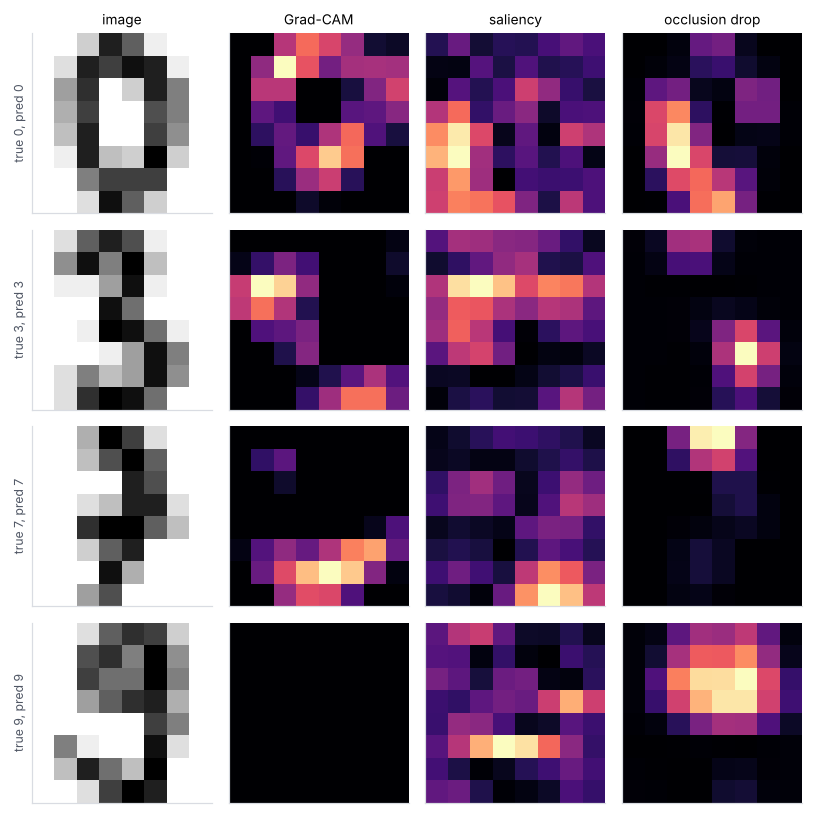

In [6]:
idx = [int(torch.nonzero(yte == d)[0]) for d in (0, 3, 7, 9)]
fig, ax = plt.subplots(4, 4, figsize=(7.5, 7.5))
for r, i in enumerate(idx):
    x = Xte[i]; cam, c = grad_cam(cnn, x); sal = saliency(cnn, x, c); occ = occlusion_map(cnn, x, c)
    for a, im, t, cmap in zip(ax[r], (x.view(8, 8).numpy(), cam, sal, occ), ("image", "Grad-CAM", "saliency", "occlusion drop"), ("gray_r", "magma", "magma", "magma")):
        a.imshow(im, cmap=cmap); a.set_xticks([]); a.set_yticks([]); a.grid(False)
        if r == 0: a.set_title(t, fontsize=9)
    ax[r, 0].set_ylabel(f"true {int(yte[i])}, pred {c}", fontsize=8)
plt.tight_layout(); plt.show()

All three methods light up the strokes that distinguish the digit, not the empty background, and Grad-CAM and occlusion agree on the broad regions. Saliency is noisier and speckled: a gradient is local, and these images have only 64 pixels so every pixel matters. On an 8 by 8 image a heat map cannot be sharp, which is a reminder that every one of these maps is a *summary*, not a proof of what the network "thinks".

### Does the explanation depend on what the model learned?

A trustworthy explanation method should change when the model's weights are replaced by random numbers. If the map barely changes, the method is showing you the *image*, not the *model*. We measure the rank correlation between the saliency of the trained network and of a randomly initialised copy of the same architecture, averaged over 30 test images, then compare with how the occlusion map ranks pixels by their effect on accuracy.

mean rank correlation, trained vs random weights (saliency): 0.043


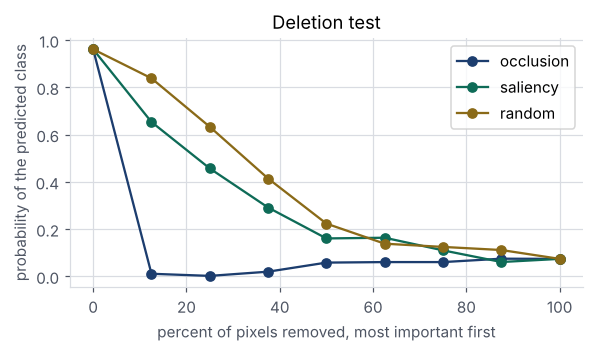

In [7]:
print("mean rank correlation, trained vs random weights (saliency):", round(sanity_randomization(cnn, Xte), 3))
# deletion test: remove the pixels each method ranks first, and watch the predicted probability
orders = {"occlusion": lambda x, c: np.argsort(-occlusion_map(cnn, x, c).ravel()), "saliency": lambda x, c: np.argsort(-saliency(cnn, x, c).ravel()),
          "random": lambda x, c: np.random.default_rng(0).permutation(64)}
curves = {k: [] for k in orders}
for i in range(40):
    x = Xte[i]; c = int(cnn(x[None]).argmax(1))
    for k, f in orders.items(): curves[k].append(deletion_curve(cnn, x, torch.as_tensor(f(x, c).copy())))
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for k, col in (("occlusion", NAVY), ("saliency", GREEN), ("random", AMBER)): ax.plot(np.linspace(0, 100, 9), np.mean(curves[k], 0), color=col, marker="o", label=k)
ax.set_xlabel("percent of pixels removed, most important first"); ax.set_ylabel("probability of the predicted class"); ax.legend(); ax.set_title("Deletion test"); plt.tight_layout(); plt.show()

The correlation with a random network is close to zero, so the saliency map is a property of the trained weights and not just of the picture. The deletion test is the stronger check: removing the pixels an explanation ranks first should destroy the prediction faster than removing pixels at random. Occlusion, which directly measures that effect, does so best: removing its top 12% of pixels takes the predicted probability from 0.96 to 0.01, against 0.64 for saliency and 0.84 for random pixels. Saliency is better than random but not by as much (the probabilities are averages over 40 test images). An explanation that fails this test should not be trusted, however good it looks.

## 2. Exact Shapley values

For a tabular model with a handful of features, a Shapley value can be computed *exactly*: for each feature, average its marginal contribution over every order in which features could be added, starting from a baseline. The key property is **efficiency**: the contributions plus the baseline prediction add up to the model's prediction. We train a small logistic model on the lending data (the next part's data) and explain one applicant.

In [8]:
D = lending_data(6000, 0); Xl = D["X"]; names = D["names"]
mu = Xl[:4000].mean(0); sd = Xl[:4000].std(0)
w = torch.zeros(5, requires_grad=True); b = torch.zeros(1, requires_grad=True); opt = torch.optim.Adam([w, b], lr=0.05)
Z = torch.tensor((Xl[:4000] - mu) / sd); yy = torch.tensor(D["y_true"][:4000], dtype=torch.float32)
for _ in range(400):
    l = F.binary_cross_entropy_with_logits(Z @ w + b, yy); opt.zero_grad(); l.backward(); opt.step()
f = lambda a: torch.sigmoid(torch.tensor(((a - mu) / sd).astype(np.float32)) @ w.detach() + b.detach()).numpy()
x0 = Xl[4000]; phi, v0, v1 = exact_shapley(f, x0, mu)
print(f"prediction at the average applicant (baseline): {v0:.3f}   prediction for this applicant: {v1:.3f}")
for n, p, xv in zip(names, phi, x0): print(f"  {n:16s} value {xv:6.2f}   contribution {p:+.3f}")
print(f"sum of contributions: {phi.sum():+.4f}   prediction minus baseline: {v1 - v0:+.4f}")

prediction at the average applicant (baseline): 0.507   prediction for this applicant: 0.351
  income           value  -0.60   contribution -0.197
  payment history  value   0.22   contribution +0.044
  debt             value  -0.00   contribution +0.000
  neighbourhood    value  -0.41   contribution +0.004
  noise            value  -1.77   contribution -0.006
sum of contributions: -0.1557   prediction minus baseline: -0.1557


The contributions add up to the difference between this applicant's prediction and the baseline, exactly, and the pure-noise column gets a contribution near zero because the model learned to ignore it. Two cautions that matter in practice. The baseline is a choice: a different baseline (the median, a typical rejected applicant) gives different numbers and a different story. And Shapley values explain the *model*, not the world: if the model leans on a proxy for a protected attribute, Shapley will faithfully report that the proxy mattered, which is the starting point of Part 5, not a justification of it. Exact computation costs $2^d$ model evaluations, which is why libraries such as SHAP use sampling or tree structure for anything with more than about a dozen features.

## 3. Calibration

A classifier is calibrated if, among the predictions it makes with confidence about 0.9, about 90% are right. Accuracy says nothing about this. We take a multilayer perceptron that is far too large for its 200 training images and trained for 300 full-batch steps, which makes it accurate but overconfident, and measure the **expected calibration error** (ECE): the weighted average gap between confidence and accuracy over ten confidence bins.

test accuracy 0.928;  mean confidence 0.971;  ECE 0.045
temperature fitted on 400 held-out training images: T = 2.15
after scaling: accuracy 0.928 (unchanged);  mean confidence 0.928;  ECE 0.009

confidence bin     before: n, accuracy      after: n, accuracy
  0.0 to 0.1              0        nan                0        nan
  0.1 to 0.2              0        nan                0        nan
  0.2 to 0.3              0        nan                0        nan
  0.3 to 0.4              0        nan                0        nan
  0.4 to 0.5              1      0.000                5      0.400
  0.5 to 0.6              5      0.600               16      0.500
  0.6 to 0.7              6      0.500               17      0.647
  0.7 to 0.8              9      0.556               12      0.750
  0.8 to 0.9             14      0.571               18      0.833
  0.9 to 1.0            324      0.969              291      0.990


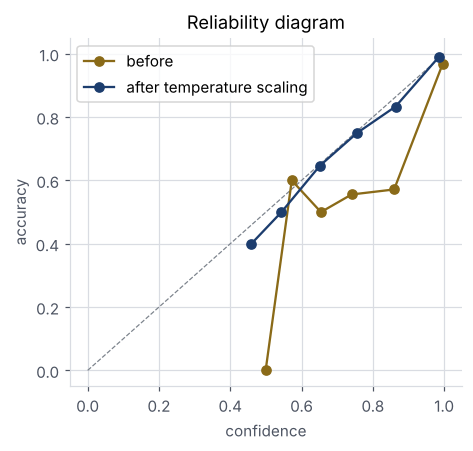

In [9]:
over = overfit_mlp(Xtr[:200], ytr[:200])
with torch.no_grad(): lt = over(Xte); lv = over(Xtr[200:600])
p = F.softmax(lt, 1).numpy(); yn = yte.numpy()
print(f"test accuracy {(lt.argmax(1) == yte).float().mean():.3f};  mean confidence {p.max(1).mean():.3f};  ECE {ece(p, yn):.3f}")
T = fit_temperature(lv, ytr[200:600]); p2 = F.softmax(lt / T, 1).numpy()
print(f"temperature fitted on 400 held-out training images: T = {T:.2f}")
print(f"after scaling: accuracy {(lt.argmax(1) == yte).float().mean():.3f} (unchanged);  mean confidence {p2.max(1).mean():.3f};  ECE {ece(p2, yn):.3f}")
print()
print("confidence bin     before: n, accuracy      after: n, accuracy")
for (c1, a1, n1), (c2, a2, n2), k in zip(reliability(p, yn), reliability(p2, yn), range(10)):
    print(f"  {k / 10:.1f} to {(k + 1) / 10:.1f} {n1:14d} {a1 if n1 else float('nan'):10.3f} {n2:16d} {a2 if n2 else float('nan'):10.3f}")
fig, ax = plt.subplots(figsize=(4.4, 4.2)); ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
for pp, lab, col in ((p, "before", AMBER), (p2, "after temperature scaling", NAVY)):
    r = reliability(pp, yn); ax.plot([a for a, b, c in r if c], [b for a, b, c in r if c], marker="o", color=col, label=lab)
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Reliability diagram"); plt.tight_layout(); plt.show()

Dividing the logits by one number leaves every prediction, and so the accuracy, exactly unchanged, but moves the confidence into line with how often the model is right: the error falls by a factor of several. Notice what this does *not* fix: calibration is measured on data that look like the data used to fit the temperature. Under shift, the next section shows, it breaks again.

## 4. Robustness and distribution shift

We corrupt the test images in controlled ways and measure the accuracy of the CNN. Each corruption has a severity knob.

In [10]:
tests = [("none", None, 0), ("noise, std 0.1", "noise", 0.1), ("noise, std 0.2", "noise", 0.2), ("noise, std 0.3", "noise", 0.3), ("blur, 1 pass", "blur", 1), ("blur, 2 passes", "blur", 2),
         ("occlude 2 x 2 patch", "occlude", 2), ("occlude 3 x 3 patch", "occlude", 3), ("brightness x 0.5", "brightness", 0.5), ("shift 1 pixel", "shift", 1)]
print(f"{'corruption':24s} {'accuracy':>9s} {'mean confidence':>16s}")
for name, kind, sev in tests:
    Xc = Xte if kind is None else corrupt(Xte, kind, sev)
    with torch.no_grad(): pr = F.softmax(cnn(Xc), 1)
    print(f"{name:24s} {(pr.argmax(1) == yte).float().mean():9.3f} {pr.max(1).values.mean():16.3f}")

corruption                accuracy  mean confidence
none                         0.933            0.909
noise, std 0.1               0.914            0.882
noise, std 0.2               0.777            0.831
noise, std 0.3               0.618            0.807
blur, 1 pass                 0.802            0.820
blur, 2 passes               0.660            0.769
occlude 2 x 2 patch          0.805            0.867
occlude 3 x 3 patch          0.577            0.844
brightness x 0.5             0.708            0.738
shift 1 pixel                0.602            0.793


Accuracy drops fast under every corruption, and the **shift by a single pixel** is the clearest warning: the digit is unchanged to a human eye, yet accuracy falls by a third. A convolutional network is not shift-invariant once pooling and a final linear layer on a coarse grid are involved, and it was never shown shifted images. Compare the second column with the first: the confidence falls much less than the accuracy, so the model is *more overconfident* under shift than on clean data.

### Can the model's own confidence warn us?

A common first defence is to treat low maximum-softmax probability as a sign that an input is unfamiliar. We measure how well that separates clean test images from (a) uniform random noise images and (b) images shifted by 3 pixels, using the area under the ROC curve (1.0 = perfect separation, 0.5 = useless).

In [11]:
rnd = torch.rand(300, 64); shifted = corrupt(Xte, "shift", 3); noisy = corrupt(Xte, "noise", 0.3)
s_in = max_softmax(cnn, Xte)
print(f"{'compared with':34s} {'AUROC':>6s}  {'mean confidence of the unfamiliar inputs':>40s}")
for name, Xo in (("uniform random images", rnd), ("shifted by 3 pixels", shifted), ("Gaussian noise, std 0.3", noisy)):
    s_o = max_softmax(cnn, Xo); print(f"{name:34s} {auroc(s_in, s_o):6.3f}  {s_o.mean():40.3f}")
print(f"{'(clean test images)':34s} {'':6s}  {s_in.mean():40.3f}")

compared with                       AUROC  mean confidence of the unfamiliar inputs
uniform random images               0.788                                     0.782
shifted by 3 pixels                 0.718                                     0.799
Gaussian noise, std 0.3             0.715                                     0.807
(clean test images)                                                           0.909


Maximum softmax is better than nothing and far from reliable. It separates clean images from uniform noise only moderately well (0.79), and does worse on the shifted and the noisy digits (about 0.72), which are the dangerous ones because they still look like digits. The lesson for deployment is not "use max-softmax" but "monitor the input distribution itself, keep a held-out set that looks like production, and measure accuracy under the shifts you expect". A confidence score is a feature of the model, and the model is exactly the thing that is wrong when the data shift.

**Try it.** Train the CNN with randomly shifted images and repeat the shift test. Fit the temperature on shifted data and see whether calibration holds on clean data. Pick a different test image and check whether the three explanation methods still agree.